# Employee Performance Analysis
**Practical Exam: Mathematics & Advanced Statistics**

Dataset: `employee_performance.csv` (4000 records). Fields: Employee_ID, Department, Age, Salary, Projects_Completed, Working_Hours, Performance_Score (0-100), Promotion_Status (Yes/No).

Goal: short theory explanations (Part A) and Python-based analysis (Part B) of employee performance and probability of promotion.

## Part A - Theory (Short Questions)

**1. Define Mean, Median, Mode with an example in the context of employee salaries.**

**Mean** is the average: the sum of all salaries divided by the number of employees. **Median** is the middle salary when all salaries are sorted; half the employees earn less and half earn more. **Mode** is the salary that occurs most often.

Example: salaries (in thousands) 30, 35, 35, 40, 120. Mean = 52, Median = 35, Mode = 35. The one very high salary pulls the mean up, so the median describes a typical employee better.

**2. Differentiate between Range and Variance with examples.**

**Range** = Maximum Value − Minimum Value. It measures the difference between the highest and lowest values in a dataset.

**Variance** measures how much the data values are spread out from the mean (average). It is calculated by taking the average of squared differences from the mean.

**Example:**

Team A Salaries = [40, 50, 60]

Team B Salaries = [10, 50, 90]

**1. Range Calculation**

Team A:
Range = 60 − 40 = **20**

Team B:
Range = 90 − 10 = **80**

**2. Population Variance Calculation**

Team A:

Mean = (40 + 50 + 60) / 3 = 50

Variance = [(40−50)² + (50−50)² + (60−50)²] / 3

Variance = (100 + 0 + 100) / 3

Variance = **66.67**

Team B:

Mean = (10 + 50 + 90) / 3 = 50

Variance = [(10−50)² + (50−50)² + (90−50)²] / 3

Variance = (1600 + 0 + 1600) / 3

Variance = **1066.67**

**Conclusion:**

Team B has a higher Range (80) and Variance (1066.67) than Team A. This means Team B salaries are more spread out, while Team A salaries are more consistent.

Range uses only the minimum and maximum values, whereas Variance uses all values in the dataset.

**3. What is the difference between Normal Distribution and Poisson Distribution?**

**Normal distribution** is for continuous data (such as performance score or height). It is bell-shaped and symmetric, defined by mean and standard deviation. **Poisson distribution** is for discrete counts of events in a fixed interval (such as projects completed per month or support tickets per day). It has one parameter, lambda, which is both its mean and variance, and it is right-skewed for small lambda.

Example: Performance_Score is approximately normal, while Projects_Completed is count data that follows a Poisson-like pattern.

**4. Explain Skewness and give one workplace-related example.**

Skewness measures the asymmetry of a distribution. Skewness = 0 means symmetric; positive skew means a long tail on the right (mean > median); negative skew means a long tail on the left (mean < median).

Workplace example: company salaries are usually positively skewed, because a small number of senior executives earn much more than most employees. The mean salary is then higher than the median.

**5. Define Conditional Probability and explain how it applies to promotions.**

Conditional probability is the probability of event A given that event B has already happened: P(A|B) = P(A and B) / P(B), with P(B) > 0.

In promotions: P(Promotion | Performance_Score > 80) = (employees promoted AND score > 80) / (employees with score > 80). It tells us how much the chance of promotion changes once we know the employee is a high performer.

**6. Explain Independent vs Mutually Exclusive Events with examples.**

**Independent events**: one event does not affect the probability of the other, so P(A and B) = P(A) x P(B). Example: an employee being born in March and the employee getting promoted.

**Mutually exclusive events** cannot happen together, so P(A and B) = 0. Example: an employee's Promotion_Status being 'Yes' and 'No' in the same review cycle, or belonging to both the IT and HR department at once. Note that mutually exclusive events with non-zero probability are never independent, because knowing one occurred tells you the other did not.

**7. What does Bayes Theorem help us do in real-world decision-making?**

Bayes Theorem, P(A|B) = P(B|A) x P(A) / P(B), updates a prior belief with new evidence to give a revised (posterior) probability. It lets us reverse a conditional probability: from P(evidence | hypothesis) to P(hypothesis | evidence).

Real-world uses: medical diagnosis (probability of a disease given a positive test), spam filtering, fraud detection, and HR analytics, for example the probability that an employee was a high performer given that they were promoted.

**8. Write a short note on PCA (Principal Component Analysis) in simple words.**

PCA is a technique that reduces many correlated variables into a few new variables called principal components. Each component is a combination of the original features, and the components are ordered so that the first captures the most variation in the data, the second captures the next most, and so on, with all components uncorrelated with each other.

It is used to simplify data, remove redundancy, speed up models and visualize high-dimensional data in 2D. For the employee data, Age, Salary, Projects_Completed, Working_Hours and Performance_Score could be compressed into 2 components that still keep most of the information. Features should be standardized before applying PCA.

## Part B - Practical (Python Programming)

### Setup: import libraries and load the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
pd.set_option("display.width", 120)
pd.set_option("display.max_columns", 20)

In [2]:
df = pd.read_csv("M:\Machine Learning\practical_Exam_PR\employee_performance.csv")
print("Shape:", df.shape)
print()
print(df.head())
print()
df.info()
print()
print("Missing values per column:")
print(df.isna().sum())

Shape: (4000, 8)

  Employee_ID  Department  Age   Salary  Projects_Completed  Working_Hours  Performance_Score Promotion_Status
0     EMP0001          HR   26   465000                  14             44               82.6               No
1     EMP0002   Marketing   22   355000                  10             44               71.9              Yes
2     EMP0003  Operations   45   965000                   9             37               61.0               No
3     EMP0004       Sales   53  1075000                   7             45               79.8              Yes
4     EMP0005          IT   30   895000                   6             35               53.7               No

<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Employee_ID         4000 non-null   str    
 1   Department          4000 non-null   str    
 2   Age                

### Step 1: Central Tendency & Dispersion
- Mean, median and mode of **Salary**
- Variance and standard deviation of **Projects_Completed** (sample statistics, `ddof=1`)

In [3]:
salary = df["Salary"]
salary_mean = salary.mean()
salary_median = salary.median()
salary_mode = salary.mode()          # can return more than one value

print(f"Salary Mean   : {salary_mean:,.2f}")
print(f"Salary Median : {salary_median:,.2f}")
print(f"Salary Mode   : {salary_mode.iloc[0]:,.0f}  (occurs {(salary == salary_mode.iloc[0]).sum()} times)")
if len(salary_mode) > 1:
    print(f"  (note: {len(salary_mode)} values tie for the mode: {list(salary_mode)})")

projects = df["Projects_Completed"]
print()
print(f"Projects_Completed Variance           : {projects.var():.4f}")
print(f"Projects_Completed Standard Deviation : {projects.std():.4f}")

Salary Mean   : 858,597.50
Salary Median : 820,000.00
Salary Mode   : 720,000  (occurs 40 times)
  (note: 4 values tie for the mode: [720000, 765000, 920000, 950000])

Projects_Completed Variance           : 8.8221
Projects_Completed Standard Deviation : 2.9702


**Interpretation:** The mean salary (858,598) is higher than the median (820,000), so a few high earners pull the average upwards and the salary distribution is slightly right-skewed. The median is therefore the better measure of a 'typical' salary. The mode (720,000, occurring 40 times) is the most common salary; four values tie for it, which is normal for a large continuous-like variable. For Projects_Completed, the standard deviation of about 2.97 projects (variance 8.82) means an employee's project count typically differs from the average (about 8) by around 3 projects, so output is moderately spread out across employees.

### Step 2: Probability & Events
- Probability of employees getting promoted
- Contingency table between Promotion_Status and Department
- Conditional probability P(Promotion | Performance_Score > 80)

In [4]:
promoted = (df["Promotion_Status"] == "Yes")
p_promo = promoted.mean()
print(f"Promoted employees : {promoted.sum()} out of {len(df)}")
print(f"P(Promotion)       = {p_promo:.4f}  ({p_promo*100:.2f}%)")

Promoted employees : 1215 out of 4000
P(Promotion)       = 0.3038  (30.38%)


**Interpretation:** P(Promotion) = 0.3038, so about 30% of employees (1215 out of 4000) were promoted, roughly 3 in every 10. This is the baseline (unconditional) probability that later conditional probabilities are compared against.

In [5]:
ct = pd.crosstab(df["Promotion_Status"], df["Department"], margins=True, margins_name="Total")
print("Contingency table (Promotion_Status x Department):")
print(ct)
print()
rate = pd.crosstab(df["Department"], df["Promotion_Status"], normalize="index") * 100
print("Promotion rate within each department (%):")
print(rate.round(2))

Contingency table (Promotion_Status x Department):
Department        Finance   HR    IT  Marketing  Operations  Sales  Total
Promotion_Status                                                         
No                    374  278   742        420         414    557   2785
Yes                   166  125   324        189         197    214   1215
Total                 540  403  1066        609         611    771   4000

Promotion rate within each department (%):
Promotion_Status     No    Yes
Department                    
Finance           69.26  30.74
HR                68.98  31.02
IT                69.61  30.39
Marketing         68.97  31.03
Operations        67.76  32.24
Sales             72.24  27.76


**Interpretation:** IT is the largest department (1066 employees), followed by Sales (771 employees). Marketing is fourth (609 employees), after Operations (611 employees). The promotion rate is similar in every department, ranging from 27.8% in Sales to 32.2% in Operations, so department has only a weak influence on promotion. Sales has the lowest rate, but the gap is small compared with the effect of performance seen in the next step.

In [6]:
high = df["Performance_Score"] > 80
n_high = high.sum()
n_high_promo = (high & promoted).sum()

p_high = n_high / len(df)
p_both = n_high_promo / len(df)
p_cond = p_both / p_high            # P(A|B) = P(A and B) / P(B)

print(f"Employees with Performance_Score > 80 : {n_high}")
print(f"  of which promoted                   : {n_high_promo}")
print(f"P(Score > 80)                = {p_high:.4f}")
print(f"P(Promotion and Score > 80)  = {p_both:.4f}")
print(f"P(Promotion | Score > 80)    = {p_cond:.4f}  ({p_cond*100:.2f}%)")
print()
low_cond = (promoted & ~high).sum() / (~high).sum()
print(f"For comparison, P(Promotion | Score <= 80) = {low_cond:.4f}  ({low_cond*100:.2f}%)")

Employees with Performance_Score > 80 : 547
  of which promoted                   : 387
P(Score > 80)                = 0.1368
P(Promotion and Score > 80)  = 0.0968
P(Promotion | Score > 80)    = 0.7075  (70.75%)

For comparison, P(Promotion | Score <= 80) = 0.2398  (23.98%)


**Interpretation:** P(Promotion | Score > 80) = 0.7075, so about 71 of every 100 employees scoring above 80 are promoted, compared with only 24.0% of those scoring 80 or below, about 3 times higher. Since P(Promotion) = 30.4% is very different from 70.7%, promotion and high performance are not independent events: a high score strongly increases the chance of promotion. Only 13.7% of employees score above 80, so top performers are rare.

### Step 3: Distributions & Visualization
- Histogram of Performance_Score with a Gaussian curve
- Skewness and kurtosis of Salary
- Q-Q plot of Projects_Completed

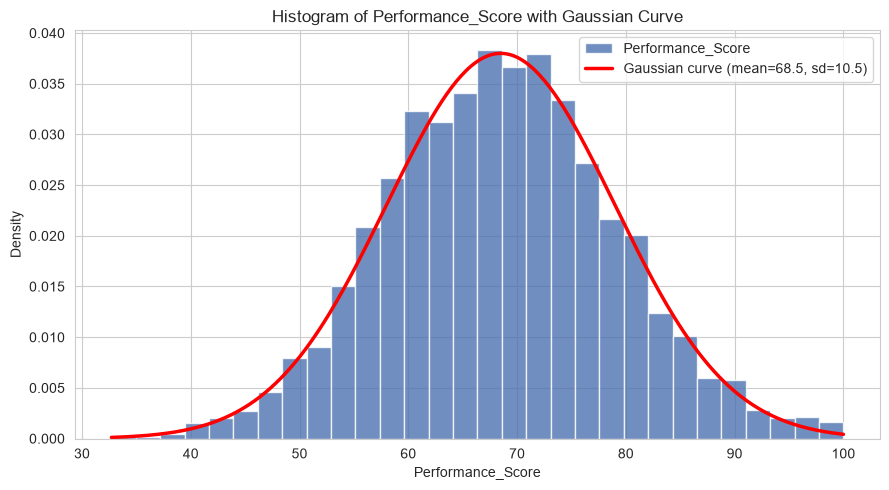

In [7]:
scores = df["Performance_Score"]
mu, sigma = scores.mean(), scores.std()
x = np.linspace(scores.min(), scores.max(), 300)

plt.figure(figsize=(9, 5))
plt.hist(scores, bins=30, density=True, color="#4C72B0", edgecolor="white", alpha=0.8, label="Performance_Score")
plt.plot(x, stats.norm.pdf(x, mu, sigma), color="red", linewidth=2.5,
         label=f"Gaussian curve (mean={mu:.1f}, sd={sigma:.1f})")
plt.title("Histogram of Performance_Score with Gaussian Curve")
plt.xlabel("Performance_Score")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

**Interpretation:** The histogram is bell-shaped and closely follows the red Gaussian curve (mean about 68.5, standard deviation about 10.5), so Performance_Score is approximately normally distributed. Most employees (about 68%) score between roughly 58 and 79, and very few score above 90 or below 40. The distribution is symmetric, so the mean can be used as a reliable measure of the typical score.

In [8]:
sal_skew = stats.skew(df["Salary"])
sal_kurt = stats.kurtosis(df["Salary"])        # excess kurtosis (Fisher): normal = 0

print(f"Salary Skewness         : {sal_skew:.4f}")
print(f"Salary Kurtosis (excess): {sal_kurt:.4f}   (Pearson kurtosis = {sal_kurt + 3:.4f}, normal = 3)")
print()
if sal_skew > 0.5:
    print("Interpretation: Salary is positively (right) skewed - a few high salaries pull the mean above the median.")
elif sal_skew < -0.5:
    print("Interpretation: Salary is negatively (left) skewed.")
else:
    print("Interpretation: Salary is roughly symmetric.")
if sal_kurt > 0:
    print("Kurtosis: heavier tails than a normal distribution (leptokurtic) - more extreme salaries.")
else:
    print("Kurtosis: lighter tails than a normal distribution (platykurtic).")

Salary Skewness         : 1.0185
Salary Kurtosis (excess): 2.2281   (Pearson kurtosis = 5.2281, normal = 3)

Interpretation: Salary is positively (right) skewed - a few high salaries pull the mean above the median.
Kurtosis: heavier tails than a normal distribution (leptokurtic) - more extreme salaries.


**Interpretation:** Skewness is 1.02, which is positive: Salary has a long right tail, because a few senior or long-serving employees earn much more than the rest. This agrees with mean > median in Step 1. The excess kurtosis is 2.23 (Pearson kurtosis 5.23, compared with 3 for a normal distribution), so the tails are heavier than normal (leptokurtic), meaning more extreme salaries than a normal distribution would predict. Salary is therefore not normal; the median is preferred for reporting, and a log transform could be used before modelling.

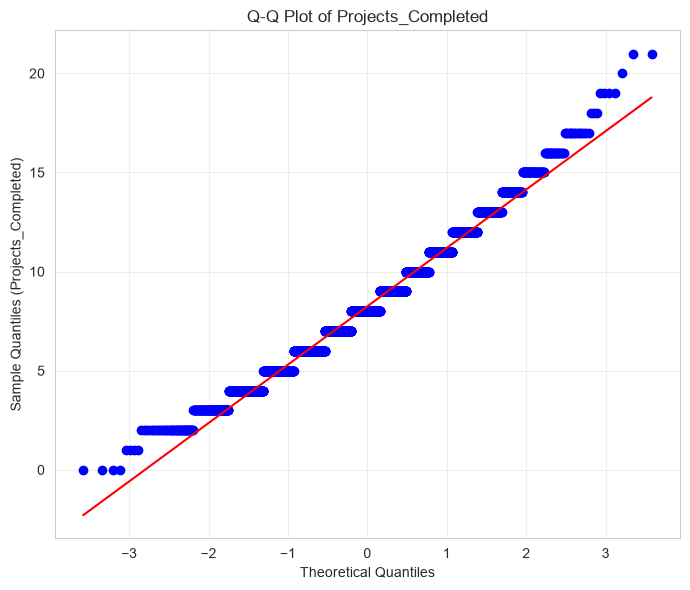

In [9]:
plt.figure(figsize=(7, 6))
stats.probplot(df["Projects_Completed"], dist="norm", plot=plt)
plt.title("Q-Q Plot of Projects_Completed")
plt.xlabel("Theoretical Quantiles")
plt.ylabel("Sample Quantiles (Projects_Completed)")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

**Interpretation:** The points lie close to the red line in the middle, so Projects_Completed is roughly normal around its centre. The points form horizontal steps because the variable is a whole-number count, and they bend away from the line at the upper end, showing a slightly heavier right tail. This is typical of count data that follows a Poisson-like distribution, so it is only approximately normal.

### Step 4: Linear Algebra Application
The first 5 employees' `[Projects_Completed, Working_Hours]` are treated as vectors. We compute the dot product of two employee vectors, the L1 and L2 norms of one employee's work vector, and the angle between two work vectors.

In [10]:
first5 = df.head(5)[["Employee_ID", "Projects_Completed", "Working_Hours"]]
print(first5.to_string(index=False))

V = first5[["Projects_Completed", "Working_Hours"]].to_numpy(dtype=float)
print()
for i, v in enumerate(V, start=1):
    print(f"Employee {i} ({first5.iloc[i-1]['Employee_ID']}) vector = {v}")

Employee_ID  Projects_Completed  Working_Hours
    EMP0001                  14             44
    EMP0002                  10             44
    EMP0003                   9             37
    EMP0004                   7             45
    EMP0005                   6             35

Employee 1 (EMP0001) vector = [14. 44.]
Employee 2 (EMP0002) vector = [10. 44.]
Employee 3 (EMP0003) vector = [ 9. 37.]
Employee 4 (EMP0004) vector = [ 7. 45.]
Employee 5 (EMP0005) vector = [ 6. 35.]


**Interpretation:** Each employee is represented as a 2-dimensional vector [Projects_Completed, Working_Hours]. Working_Hours (35 to 45) is much larger in magnitude than Projects_Completed (6 to 14), so the hours component dominates the length and direction of each vector.

In [11]:
a, b = V[0], V[1]      # Employee 1 and Employee 2

# Dot product
dot = np.dot(a, b)
print(f"Dot product a.b = {a[0]:.0f}*{b[0]:.0f} + {a[1]:.0f}*{b[1]:.0f} = {dot:.0f}")

# Norms of Employee 1's work vector
norm1 = np.linalg.norm(a, ord=1)     # |x| + |y|
norm2 = np.linalg.norm(a, ord=2)     # sqrt(x^2 + y^2)
print(f"Norm 1 (L1) of Employee 1 = {norm1:.4f}")
print(f"Norm 2 (L2) of Employee 1 = {norm2:.4f}")

# Angle between the two vectors: cos(theta) = a.b / (|a||b|)
cos_theta = dot / (np.linalg.norm(a) * np.linalg.norm(b))
angle_deg = np.degrees(np.arccos(np.clip(cos_theta, -1, 1)))
print(f"cos(theta) = {cos_theta:.6f}")
print(f"Angle between Employee 1 and Employee 2 = {angle_deg:.4f} degrees")

Dot product a.b = 14*10 + 44*44 = 2076
Norm 1 (L1) of Employee 1 = 58.0000
Norm 2 (L2) of Employee 1 = 46.1736
cos(theta) = 0.996426
Angle between Employee 1 and Employee 2 = 4.8459 degrees


**Interpretation:** The dot product of Employee 1 and 2 is 2076. It is large and positive, which shows the two vectors point in a similar direction (similar work patterns), though its size is dominated by the hours component (44 x 44 = 1936). Norm 1 (58) is the sum of the absolute values 14 + 44, which is the total of projects and hours. Norm 2 (46.17) is the straight-line (Euclidean) length of the vector. The angle of 4.85 degrees (cos = 0.9964) is very small, so the two employees have almost the same work profile.

In [12]:
# Bonus: angle between every pair of the first 5 employees
norms = np.linalg.norm(V, axis=1)
cos_m = (V @ V.T) / np.outer(norms, norms)
angle_m = np.degrees(np.arccos(np.clip(cos_m, -1, 1)))
labels = [f"E{i}" for i in range(1, 6)]
print("Angle matrix (degrees):")
print(pd.DataFrame(angle_m, index=labels, columns=labels).round(3))

Angle matrix (degrees):
       E1     E2     E3     E4     E5
E1  0.000  4.846  3.979  8.808  7.923
E2  4.846  0.000  0.867  3.962  3.077
E3  3.979  0.867  0.000  4.829  3.944
E4  8.808  3.962  4.829  0.000  0.886
E5  7.923  3.077  3.944  0.886  0.000


**Interpretation:** All pairwise angles are below 9 degrees, so the first five employees have very similar work vectors. This is because Working_Hours is similar for everyone and dominates the direction. Employees 2 and 3 (0.87 degrees) and 4 and 5 (0.89 degrees) are the most alike, and Employees 1 and 4 (8.81 degrees) are the most different. In practice, the features should be standardized before comparing employees by vector angle.

## Key Insights :

### 1. Overall promotion probability is 30.4%, so roughly 1 in 3 employees gets promoted.
### 2. Employees with Performance_Score > 80 have a 70.7% chance of promotion, versus 24.0% for those scoring 80 or below (3.0x higher).
### 3. Operations has the highest promotion rate (32.2%) and Sales the lowest (27.8%).
### 4. Projects_Completed has a correlation of 0.61 with Performance_Score, while Working_Hours has 0.17: completing projects matters more than long hours.
### 5. Salary is right-skewed (skewness = 1.02, mean 858,598 > median 820,000); promoted employees earn on average 871,745 vs 852,862 for non-promoted.